# Predicting answer correctness from eye movements

The question: from how a participant looks at the question and the four answer options, can we tell
whether they will choose the correct answer? The data are Study 1: 360 participants and 19,436
trials, one row per trial, of which about 84% were answered correctly. A logistic regression with
balanced class weights predicts `is_correct` from ten or twelve eye-movement features, and its predicted
probability is read as a stand-in for how confident the participant was. The accuracy the paper
reports is cross-validated over ten folds that hold out new participants, new paragraphs, or both;
the coefficients come from one fit on all trials, with intervals from a bootstrap that resamples
whole participants. Scores are balanced accuracy (the mean of the hit rates on correct and on wrong
answers), because most answers are correct and plain accuracy would reward always guessing
"correct". Two caveats to keep in mind: the model fills missing pupil values (areas the participant
never looked at) with 0, a stated choice, and the spread across folds understates the real
uncertainty, because the folds share most of their training data.

The models fitted one participant at a time (`person_variance/`) and Study 2 (`knowledge_regimes/`)
have their own notebooks. This notebook only shows; it saves nothing.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "__init__.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.lib.plotting.output import set_output_defaults
set_output_defaults(save=False)   # this notebook only shows; it saves nothing

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

import src.config.columns as Con
from src.config.datasets import dataset, HUNTERS_REFOLDED_DIR, GATHERERS_REFOLDED_DIR
from src.features.build import load_model_ready, load_model_input
from src.modeling.feature_sets import SELECT_1_COLS, LAST_CONFIRM_COMPACT
from src.modeling.models.logreg_model import TrialLevelLogRegModel, imputed_cell_counts
from src.modeling.crossval import run_cross_validation_on_combined_folds
from src.modeling.evaluate import collect_logreg_coef_summaries
from src.analyses.correctness_prediction.run import run_full_features_correctness_bundle
from src.analyses.correctness_prediction.plots.coefficients import plot_coef_summary_barh
from src.analyses.correctness_prediction.plots.cv_comparison import plot_cv_metric_by_regime_pretty
from src.analyses.correctness_prediction.plots.feature_ranks import plot_feature_correlation_heatmap

trial_df = load_model_ready()                           # one row per trial, features + is_correct
word_df = load_model_input(dataset("l1"), verbose=False)  # one row per word; the single split needs it

## 1. The trial table and the two feature sets

Each row is one trial: one participant answering one question. `is_correct` is what the model
predicts. Feature names read `<measure>__<area>`: `correct` is the correct answer, `wrong_mean` the
average over the three wrong ones, `contrast` the first minus the second, and `question` the
question text.

Two feature sets are used throughout:

* **ten attention features** (`SELECT_1_COLS`), picked by hand to be few and to cover the behaviours
  the design targets: the share of looking time on the correct answer and on the question, how much
  of the correct answer was skipped, how often the correct answer was revisited (and how much more
  than the wrong ones), fixations per word on the question and on the wrong answers, pupil size on
  the correct answer, whether the scan ended by going back to the area just left (`has_xyx`), and
  how many times an answer was selected before confirming (`ANSWER_PRESS_NUMBER`);
* the same ten **plus two "last look" indicators** (`LAST_CONFIRM_COMPACT`): whether the last area
  looked at before confirming was the correct answer, or the question. This twelve-feature model
  is the paper's best.

In [2]:
print(f"{len(trial_df):,} trials, {trial_df[Con.PARTICIPANT_ID].nunique()} participants, "
      f"{trial_df[Con.IS_CORRECT_COLUMN].mean():.1%} answered correctly")

FEATURE_SETS = {
    "select_1": SELECT_1_COLS,                                          # ten attention features
    "select_1_plus_last_confirm": SELECT_1_COLS + LAST_CONFIRM_COMPACT,  # + where the last look landed
}
HEADLINE = FEATURE_SETS["select_1_plus_last_confirm"]

display(trial_df[HEADLINE].describe().T[["count", "mean", "std", "min", "max"]].round(3))

19,436 trials, 360 participants, 84.1% answered correctly


,count,mean,std,min,max
area_dwell_proportion__correct,19436.0,0.323,0.142,0.000,1.000
area_dwell_proportion__question,19436.0,0.050,0.077,0.000,1.000
skip_rate__correct,19436.0,0.356,0.214,0.000,1.000
has_xyx,19436.0,0.273,0.446,0.000,1.000
ANSWER_PRESS_NUMBER,19436.0,1.306,0.956,1.000,31.000
num_label_visits__correct,19436.0,2.074,1.069,0.000,14.000
num_label_visits__contrast,19436.0,0.553,0.886,-6.000,7.333
mean_fixations_count__question,19436.0,0.170,0.290,0.000,8.125
mean_fixations_count__wrong_mean,19436.0,0.841,0.583,0.000,10.833
mean_max_fix_pupil_size_z__correct,19183.0,0.176,0.847,-3.404,4.459


The `count` column above is short of 19,436 only for the pupil feature: a trial where the correct
answer was never looked at has no pupil value there. The model fills those cells with 0 (in
z-score units, "this participant's average pupil size"), which is an assumption rather than a
measurement. This is how many cells that is, per feature:

In [3]:
imputed_cell_counts(trial_df, HEADLINE)

mean_max_fix_pupil_size_z__correct    253
dtype: int64

## 2. Cross-validated accuracy: the paper's numbers

Ten folds, fixed in advance (`data/cv_folds/`). In each fold the model is trained on one set of
participants reading one set of paragraphs, then scored on three kinds of held-out trials: a
**new paragraph** read by a training participant (`new_item`), a **new participant** reading a
training paragraph (`new_subject`), and a new participant reading a new paragraph (`both`, the
strictest test). Each held-out kind is split into two halves (validation and test); nothing is
tuned, so both halves are simply held-out data and are pooled here.

The table gives one row per model and kind of novelty: `mean_balanced_accuracy` is the mean over
the ten folds, weighted by how many trials each fold scored, and `std_balanced_accuracy` its
spread across folds and halves. Chance is 0.5.

In [4]:
# The fold files name paragraphs by `text_id`, which the trial table does not carry; the
# word-level frame does. One row per trial is all the fold matching needs.
trial_ids = word_df[[Con.PARTICIPANT_ID, Con.TRIAL_ID, Con.TEXT_ID_COLUMN]].drop_duplicates()
assert len(trial_ids) == len(trial_df), "expected exactly one paragraph per trial"

cv_out = run_cross_validation_on_combined_folds(
    trial_ids,
    fold_dirs=[HUNTERS_REFOLDED_DIR, GATHERERS_REFOLDED_DIR],  # both groups' folds, pooled
    model_builders={name: TrialLevelLogRegModel for name in FEATURE_SETS},
    feature_cols_by_model=FEATURE_SETS,
    target_col=Con.IS_CORRECT_COLUMN,
    n_folds=10,
    trial_df=trial_df,
)

cv_out.summary_by_novelty_df[[
    "model", "novelty", "folds", "total_n_eval",
    "mean_balanced_accuracy", "std_balanced_accuracy", "mean_accuracy", "splits_pooled",
]].round(3)

,model,novelty,folds,total_n_eval,mean_balanced_accuracy,std_balanced_accuracy,mean_accuracy,splits_pooled
0,select_1,both,10,7776,0.795,0.046,0.804,test+val
1,select_1,new_item,10,31096,0.790,0.015,0.796,test+val
2,select_1,new_subject,10,31096,0.789,0.012,0.796,test+val
3,select_1_plus_last_confirm,both,10,7776,0.835,0.037,0.814,test+val
4,select_1_plus_last_confirm,new_item,10,31096,0.827,0.013,0.807,test+val
5,select_1_plus_last_confirm,new_subject,10,31096,0.829,0.022,0.808,test+val


The same scores split into the six held-out regimes, for each model. Bars are the mean over folds;
the error bars are a 95% interval across folds, which is narrower than the real uncertainty
because the folds share most of their training data. The "both new" bars are the smallest samples
(a few hundred trials per fold), so they move the most.

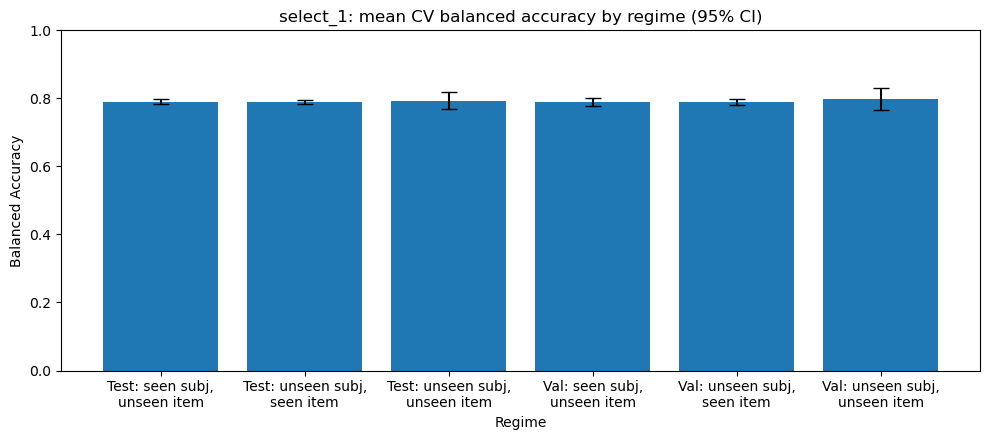

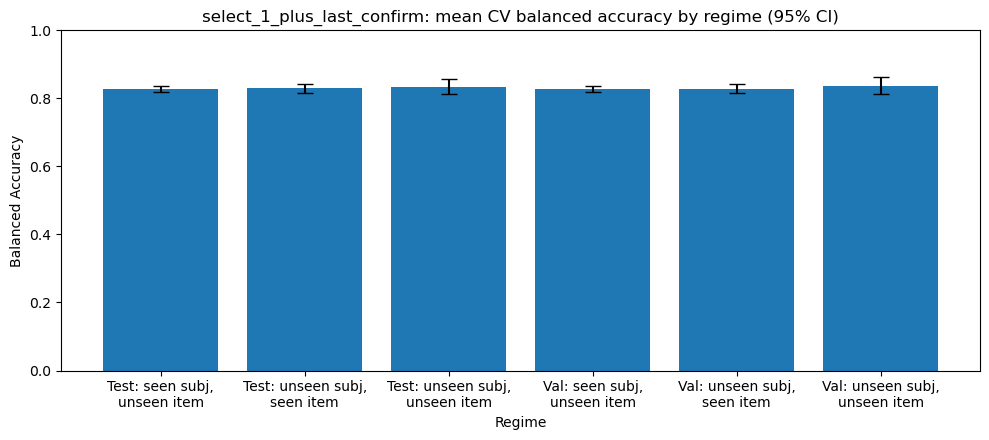

In [5]:
for name in FEATURE_SETS:
    plot_cv_metric_by_regime_pretty(cv_out, model_name=name, figsize=(10, 4.5))

## 3. The coefficients: one fit on all trials

The coefficients the paper reports come from one fit on all 19,436 trials, not from the folds.
Features are standardised first, so each coefficient is the change in log-odds of a correct answer
for one standard deviation of that feature; positive means "more of this, more likely correct".
The 95% intervals come from a bootstrap that resamples whole participants (5,000 resamples) and
refits the model each time, so trials from the same person are not treated as independent. This
takes a couple of minutes.

In [6]:
coef_by_set = collect_logreg_coef_summaries(
    trial_df,
    FEATURE_SETS,
    ci_method="bootstrap",
    ci_cluster="cluster",   # resample participants, not trials
)

coef_by_set["select_1_plus_last_confirm"][
    ["feature", "coef", "ci_low", "ci_high", "odds_ratio", "sig_ci"]
].round(3)

,feature,coef,ci_low,ci_high,odds_ratio,sig_ci
0,last_before_confirm_correct,1.213,1.127,1.302,3.363,True
1,area_dwell_proportion__correct,0.940,0.846,1.038,2.560,True
2,mean_fixations_count__wrong_mean,-0.497,-0.601,-0.400,0.608,True
3,num_label_visits__contrast,0.364,0.247,0.487,1.439,True
4,num_label_visits__correct,-0.268,-0.410,-0.134,0.765,True
5,skip_rate__correct,-0.241,-0.309,-0.173,0.786,True
6,has_xyx,-0.231,-0.284,-0.179,0.794,True
7,area_dwell_proportion__question,0.202,0.132,0.288,1.223,True
8,mean_fixations_count__question,-0.190,-0.278,-0.111,0.827,True
9,mean_max_fix_pupil_size_z__correct,-0.182,-0.239,-0.127,0.833,True


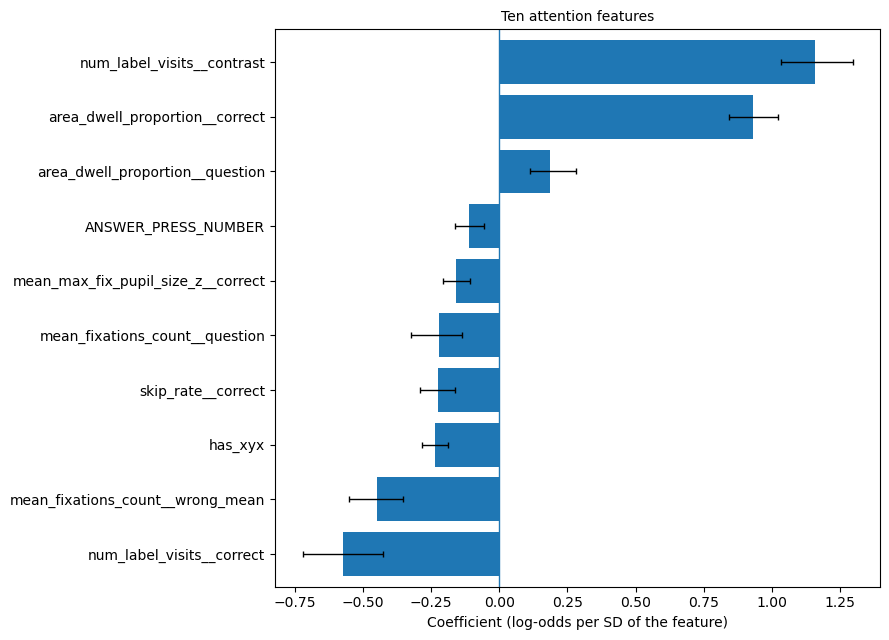

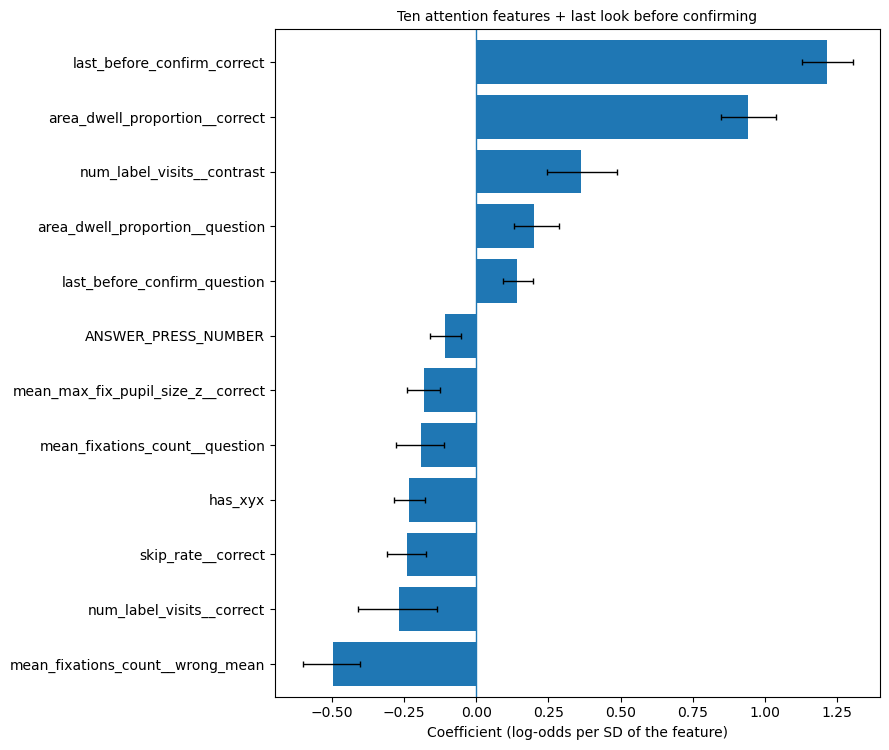

In [7]:
titles = {
    "select_1": "Ten attention features",
    "select_1_plus_last_confirm": "Ten attention features + last look before confirming",
}
for name, coef in coef_by_set.items():
    plot_coef_summary_barh(
        coef,
        significant_only=False,
        title=titles[name],
        xlabel="Coefficient (log-odds per SD of the feature)",
        ylabel="",
        save=False,
    )

## 4. One train/test split, to see what the model outputs

`run_full_features_correctness_bundle` fits the twelve-feature model on **one** fold's training
trials (fold 0) and scores it on that fold's test trials of new participants reading new
paragraphs. This is one split, not the paper's numbers: it is here to show the model's outputs on
held-out trials. It prints the scores and draws:

* the **confusion matrix**, as shares of each true outcome and as counts (0 = wrong, 1 = correct);
* the **predicted probability** of a correct answer, split by what actually happened. This is the
  figure the "probability as confidence" reading rests on: the further apart the two histograms,
  the better the model separates the two outcomes;
* the **coefficients** of this one fit, all and those whose interval excludes 0. These intervals
  are quick Wald intervals that treat each trial as independent, so they are narrower than the
  bootstrap ones above and are not the paper's.

Loading cached features from E:\Technion\QA PROJECT\programming\QA_eyetracking_workspace\data\datasets\l1_onestop\features\model_ready.csv
MODEL: trial_level_log_reg
----------------------------------------------------------------------
Number of test trials: 720
Accuracy: 0.843
Balanced accuracy: 0.834
Positive (correct) trials: 625
Negative (incorrect) trials: 95

Precision / Recall / F1 (per class):
         precision  recall    f1  support
class_0      0.448   0.821 0.580       95
class_1      0.969   0.846 0.904      625

Averages:
  macro    P/R/F1: 0.709 / 0.834 / 0.742
  weighted P/R/F1: 0.900 / 0.843 / 0.861

ROC-AUC: 0.917
Average precision (PR-AUC): 0.987

Loading cached features from E:\Technion\QA PROJECT\programming\QA_eyetracking_workspace\data\datasets\l1_onestop\features\model_ready.csv
training trials: 11,711   held-out test trials: 720


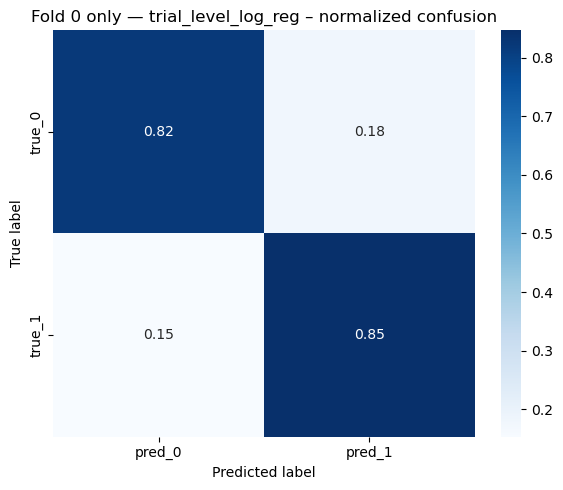

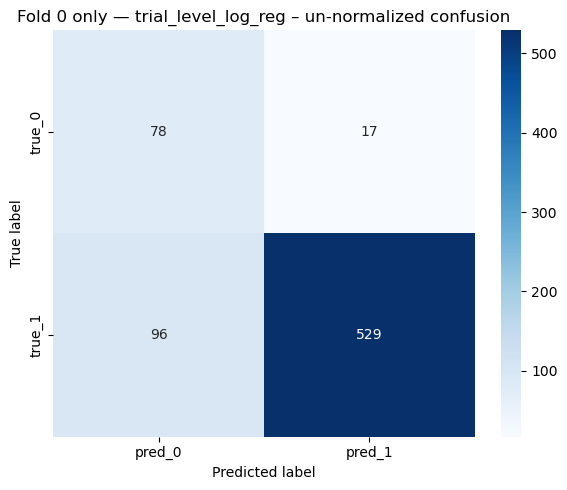

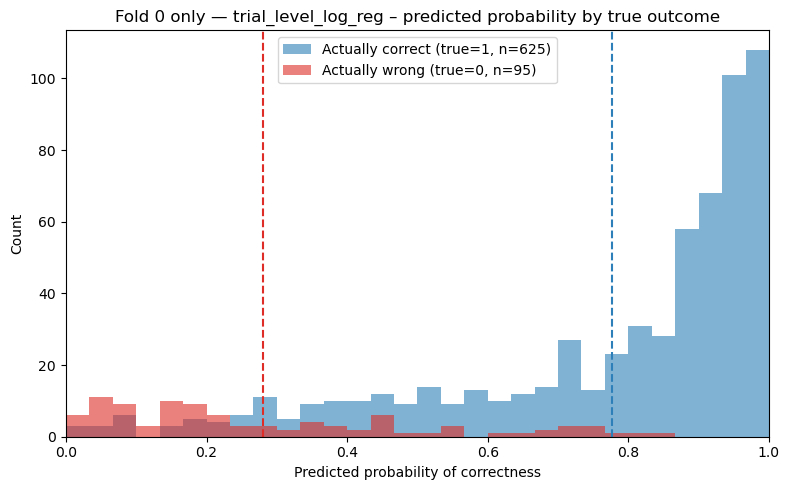

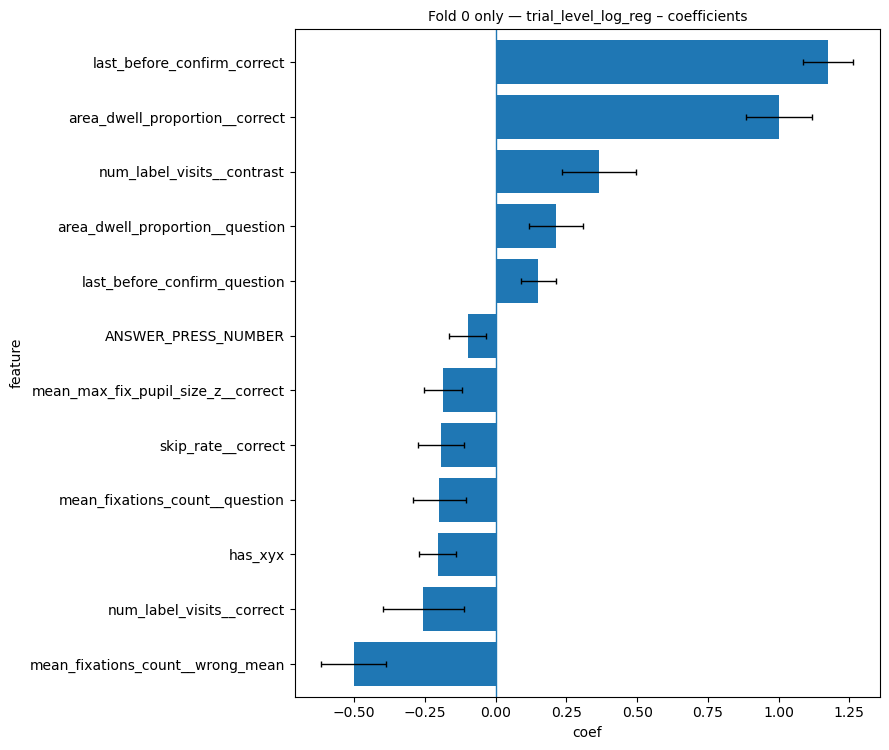

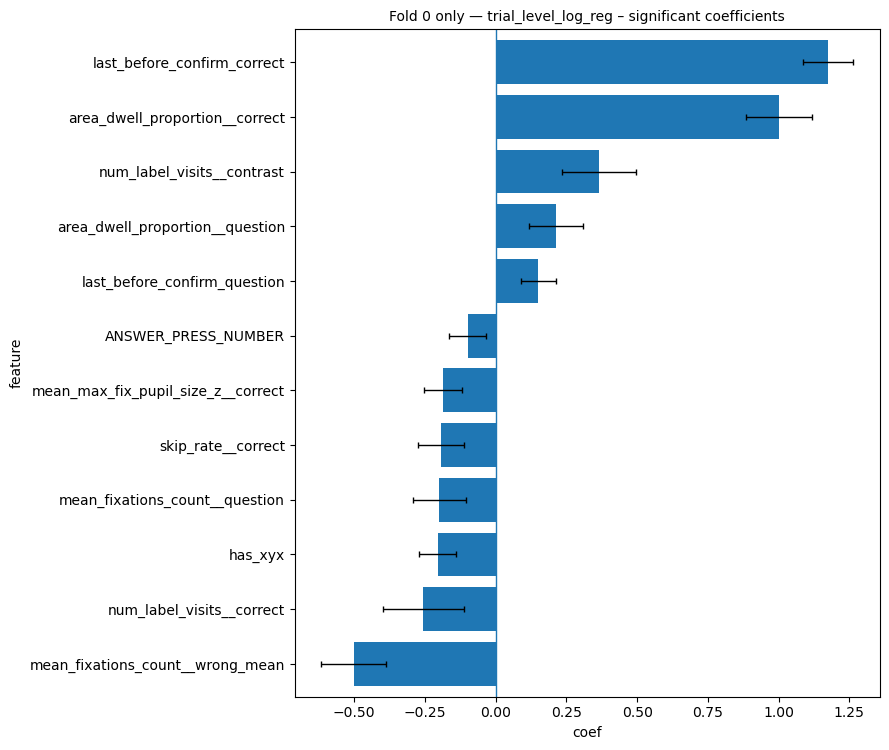

In [8]:
split = run_full_features_correctness_bundle(
    word_df,
    ["both"],                 # held out: new participants reading new paragraphs
    test_split="test",
    fold=0,
    feature_cols=HEADLINE,
    title_prefix="Fold 0 only",
    save=False,
)
# The bundle also draws the feature correlations, at 30 x 30 inches -- too large to read here.
# It is the last figure drawn; it is closed and redrawn at a readable size below.
plt.close(plt.gcf())

print(f"training trials: {len(split['train_df']):,}   held-out test trials: {len(split['test_df']):,}")

Finally, how the twelve features correlate with each other over all trials (Pearson, with
correlated features placed next to each other, and missing pupil values filled with 0 as the model
fills them). Strongly correlated features share their effect, so their coefficients should be read
together rather than one by one. `num_label_visits__correct` and `num_label_visits__contrast`, for
instance, are built from the same count (the contrast is the correct answer's value minus the wrong
answers' mean).

,skip_rate__correct,mean_max_fix_pupil_size_z__correct,area_dwell_proportion__correct,has_xyx,last_before_confirm_correct,num_label_visits__correct,num_label_visits__contrast,last_before_confirm_question,ANSWER_PRESS_NUMBER,mean_fixations_count__wrong_mean,area_dwell_proportion__question,mean_fixations_count__question
skip_rate__correct,1.00,-0.14,-0.26,-0.06,-0.10,-0.29,-0.19,0.02,-0.05,-0.33,-0.01,-0.14
mean_max_fix_pupil_size_z__correct,-0.14,1.00,0.10,0.04,0.07,0.22,0.15,-0.01,0.05,0.15,0.06,0.08
area_dwell_proportion__correct,-0.26,0.10,1.00,-0.00,0.27,-0.01,0.27,-0.04,-0.04,-0.35,-0.18,-0.19
has_xyx,-0.06,0.04,-0.00,1.00,0.09,0.29,0.25,-0.07,0.04,0.09,0.03,0.06
last_before_confirm_correct,-0.10,0.07,0.27,0.09,1.00,0.20,0.48,-0.19,-0.02,-0.15,-0.06,-0.08
num_label_visits__correct,-0.29,0.22,-0.01,0.29,0.20,1.00,0.71,-0.02,0.16,0.46,0.12,0.33
num_label_visits__contrast,-0.19,0.15,0.27,0.25,0.48,0.71,1.00,-0.03,0.03,-0.08,0.04,0.04
last_before_confirm_question,0.02,-0.01,-0.04,-0.07,-0.19,-0.02,-0.03,1.00,-0.01,-0.00,0.15,0.07
ANSWER_PRESS_NUMBER,-0.05,0.05,-0.04,0.04,-0.02,0.16,0.03,-0.01,1.00,0.17,0.03,0.11
mean_fixations_count__wrong_mean,-0.33,0.15,-0.35,0.09,-0.15,0.46,-0.08,-0.00,0.17,1.00,0.10,0.40


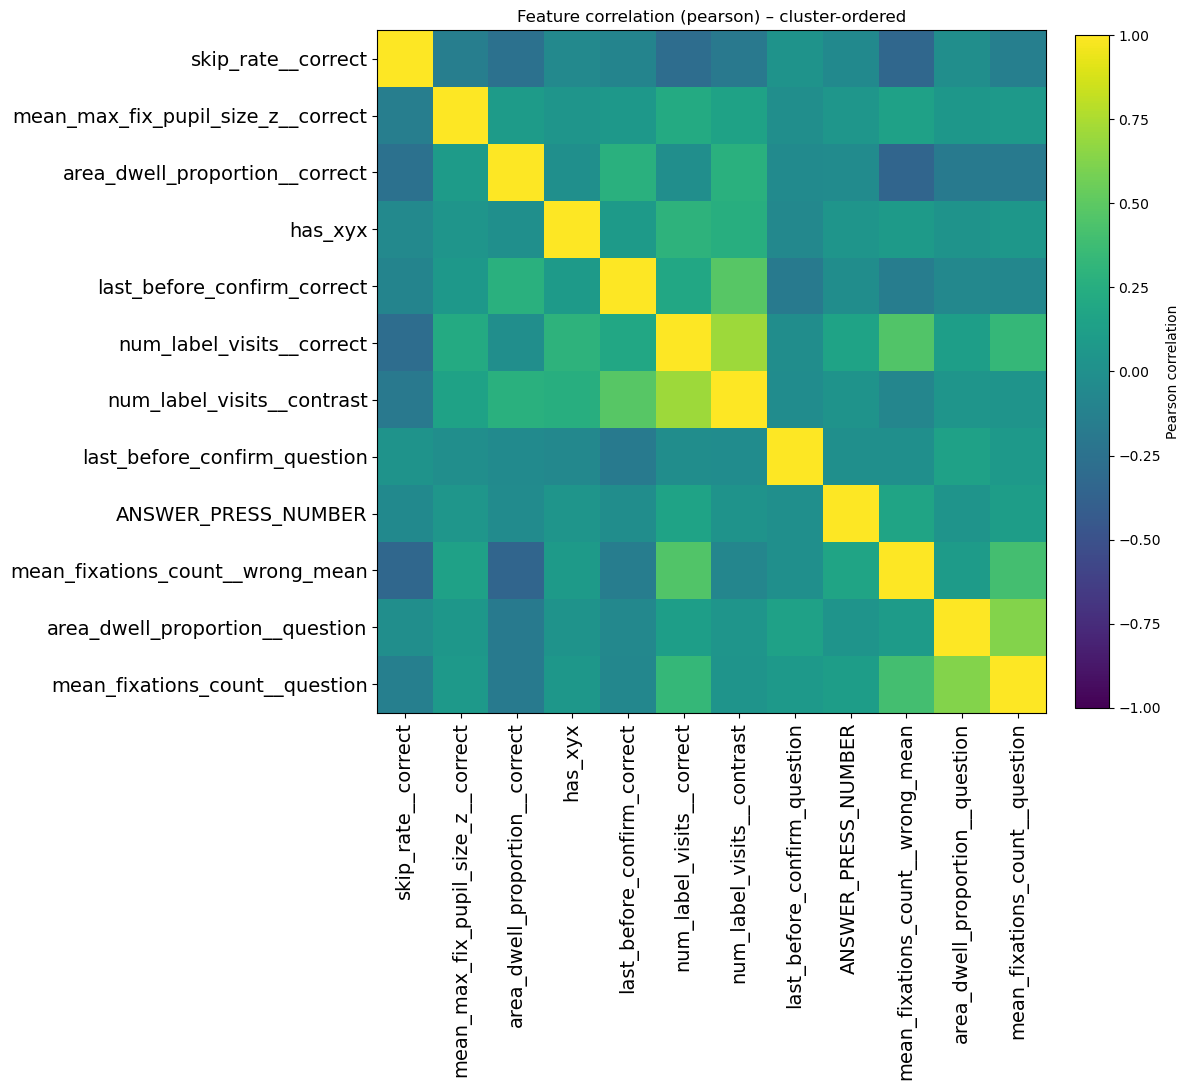

In [9]:
_, corr, _ = plot_feature_correlation_heatmap(
    trial_df,
    feature_cols=HEADLINE,
    method="pearson",
    cluster_order=True,
    figsize=(12, 11),
    save=False,
)
corr.round(2)